In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, random, logging

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,1")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.append("../..")

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from rich.console import Console
from rich.theme import Theme
from rich.markup import escape

from src.utils import logging_utils

console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)


In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-32B-Instruct"
mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
    cache_dir="/share/NFS/models"
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")

2026-09-17 09:56:14 src.utils.env_utils ERROR    env.yml not found in /share/NFS/u/sfeucht/goals!
Setting MODEL_ROOT="". Models will now be downloaded to conda env cache, if not already there
Other defaults are set to:
    DATA_DIR = "data"
    RESULTS_DIR = "results"
    HPARAMS_DIR = "hparams"
2026-09-17 09:56:14 src.models WARNING  Qwen/Qwen2.5-32B-Instruct not found in 
If not found in cache, model will be downloaded from HuggingFace to cache directory: None
2026-09-17 09:56:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-17 09:56:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-32B-Instruct/5ede1c97bbab6ce5cda5812749b4c0bdf79b18dd/config.json?%2FQwen%2FQwen2.5-32B-Instruct%2Fresolve%2Fmain%2Fconfig.json=&etag=%22989289c4009026e35063c943c2a228e2c0873d31%22 "HTTP/1.1 200 OK"
2026-09-17 09:56:14 httpx INFO     HTTP Request: HEAD htt

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

2026-09-17 09:56:15 httpx INFO     HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-32B-Instruct/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-09-17 09:56:15 httpx INFO     HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-32B-Instruct/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
2026-09-17 09:56:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-32B-Instruct/resolve/main/vocab.json "HTTP/1.1 307 Temporary Redirect"
2026-09-17 09:56:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-32B-Instruct/5ede1c97bbab6ce5cda5812749b4c0bdf79b18dd/vocab.json?%2FQwen%2FQwen2.5-32B-Instruct%2Fresolve%2Fmain%2Fvocab.json=&etag=%224783fe10ac3adce15ac8f358ef5462739852c569%22 "HTTP/1.1 200 OK"
2026-09-17 09:56:15 httpx INFO     HTTP Request: GET https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-32B-Instruct/5ede1c97bbab6ce5cda5812749b4

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

2026-09-17 09:56:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-32B-Instruct/resolve/main/merges.txt "HTTP/1.1 307 Temporary Redirect"
2026-09-17 09:56:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-32B-Instruct/5ede1c97bbab6ce5cda5812749b4c0bdf79b18dd/merges.txt?%2FQwen%2FQwen2.5-32B-Instruct%2Fresolve%2Fmain%2Fmerges.txt=&etag=%2220024bfe7c83998e9aeaf98a0cd6a2ce6306c2f0%22 "HTTP/1.1 200 OK"
2026-09-17 09:56:15 httpx INFO     HTTP Request: GET https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-32B-Instruct/5ede1c97bbab6ce5cda5812749b4c0bdf79b18dd/merges.txt?%2FQwen%2FQwen2.5-32B-Instruct%2Fresolve%2Fmain%2Fmerges.txt=&etag=%2220024bfe7c83998e9aeaf98a0cd6a2ce6306c2f0%22 "HTTP/1.1 200 OK"


merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (3 outputs left out)

Could not cache non-existence of file. Will ignore error and continue. Error: [Errno 13] Permission denied: '/share/NFS/models/models--Qwen--Qwen2.5-32B-Instruct/.no_exist/5ede1c97bbab6ce5cda5812749b4c0bdf79b18dd/adapter_config.json'


2026-09-17 09:56:16 huggingface_hub.file_download ERROR    Could not cache non-existence of file. Will ignore error and continue. Error: [Errno 13] Permission denied: '/share/NFS/models/models--Qwen--Qwen2.5-32B-Instruct/.no_exist/5ede1c97bbab6ce5cda5812749b4c0bdf79b18dd/adapter_config.json'


Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-09-17 09:56:44 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-17 09:56:44 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-32B-Instruct/5ede1c97bbab6ce5cda5812749b4c0bdf79b18dd/generation_config.json?%2FQwen%2FQwen2.5-32B-Instruct%2Fresolve%2Fmain%2Fgeneration_config.json=&etag=%22bf077f03dc569cfb8a90b3ec1ad20365a620bad6%22 "HTTP/1.1 200 OK"
2026-09-17 09:56:44 src.models INFO     loaded model <Qwen/Qwen2.5-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


In [4]:
from src.goals.head_loc_attn import HeadMask
def get_mask_bin(heads):
    """HeadMask (on CPU) with 1.0 for `heads`, 0.0 elsewhere. Layer index space is `layers`."""
    hm = HeadMask(mt.n_layer, mt.model.config.num_attention_heads)
    with torch.no_grad():
        hm.values.zero_()
        for (l, h) in heads:
            hm.values[l, h] = 1.0
    return hm


In [6]:
import json, os, torch
from src.goals.head_loc_attn import HeadMask

# don't actually have the scores here so this is claude's quick fix 
SLUG = MODEL_NAME.split("/")[-1]
HEADS_JSON = os.path.join("../..", "head_sets", SLUG, "goal__lam20_thr0.9_band25-56.json")
goal_heads = [(int(l), int(h)) for l, h in json.load(open(HEADS_JSON))]

LAYERS = list(range(mt.n_layer))
mask = get_mask_bin(goal_heads)   # binary stand-in for the trained mask
threshold = 0.9
print(f"  Active heads: {len(goal_heads)}  (layers {min(l for l,_ in goal_heads)}–{max(l for l,_ in goal_heads)})")

  Active heads: 108  (layers 29–55)


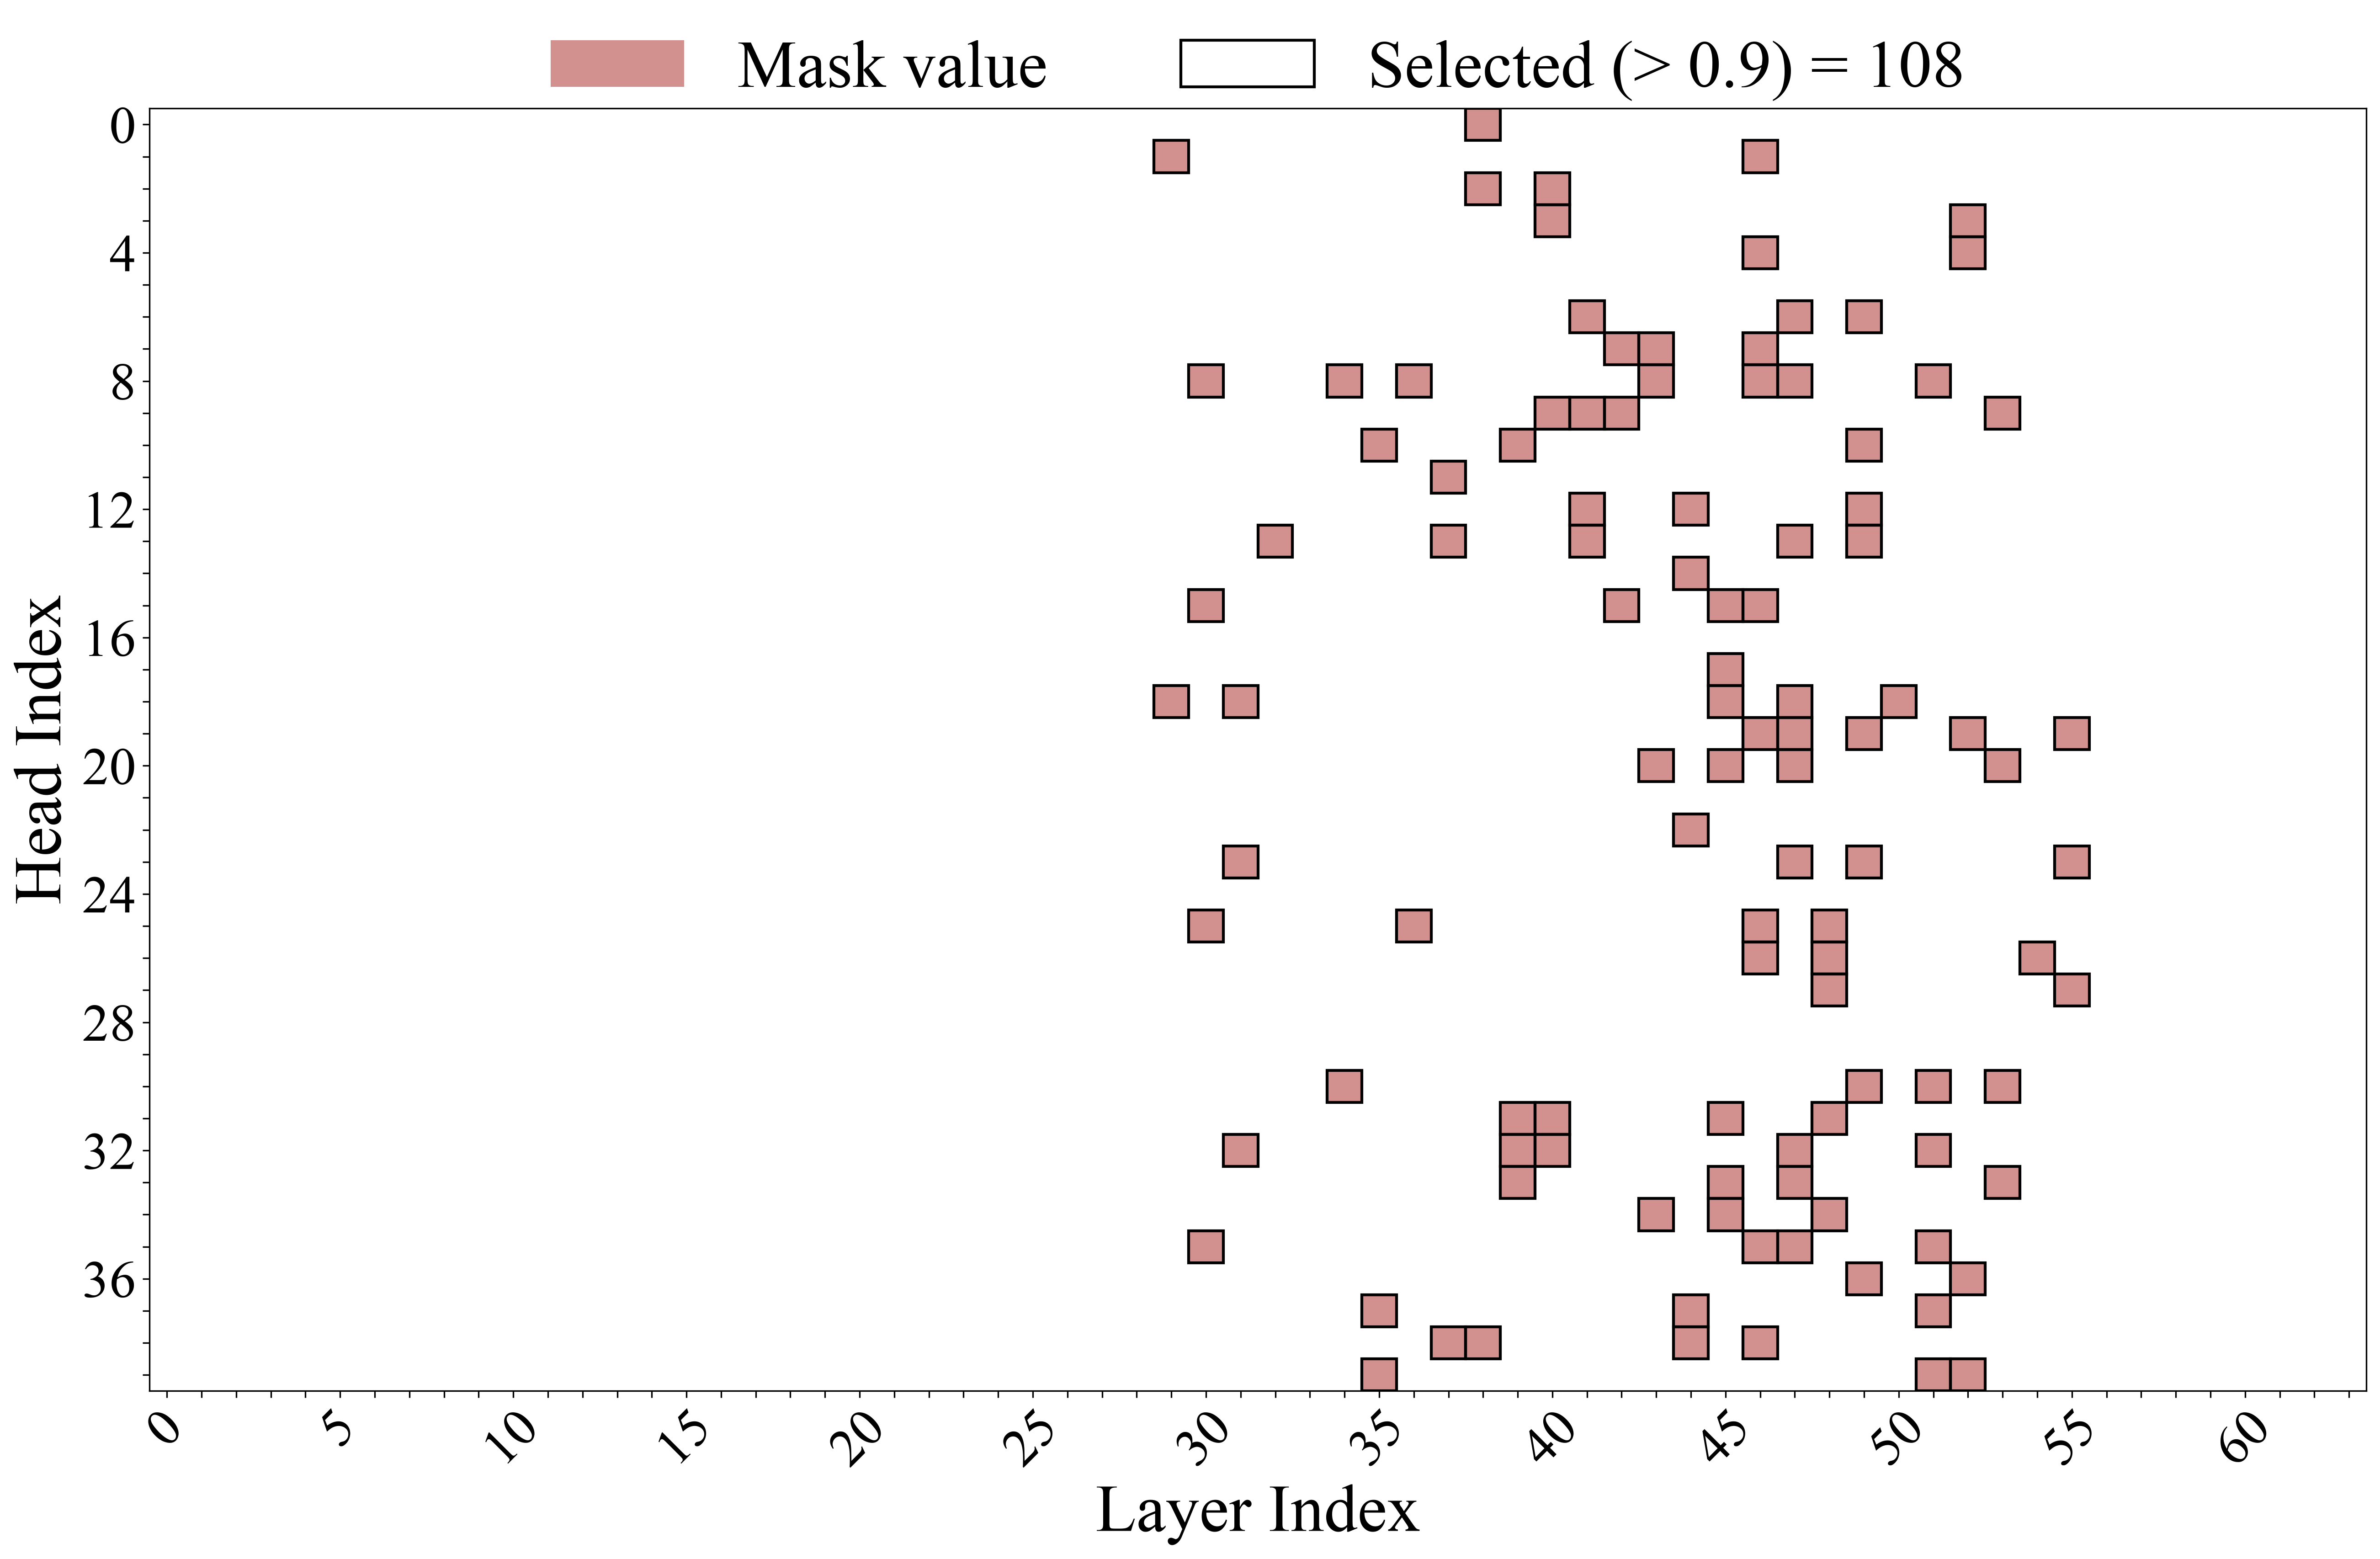

In [7]:
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from matplotlib import patches

plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 28
MEDIUM_SIZE = 35
BIGGER_SIZE = 40

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)


def get_ticks(ticks, skip=5, offset=0):
    ret = []
    for i in ticks:
        actual_layer = i + offset
        if actual_layer % skip == 0:
            ret.append(str(actual_layer))
        else:
            ret.append("")
    return ret


_n_heads = mt.config.num_attention_heads
_n_layer = mt.n_layer

# Build continuous mask matrix: shape (n_heads, n_layer)
# Layers outside the optimized range stay 0.
function_mask = torch.zeros((_n_heads, _n_layer), dtype=torch.float32)
for i, layer_idx in enumerate(LAYERS):
    function_mask[:, layer_idx] = mask.values[i].detach().cpu()

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 12))

colors = ["white", "#BF625E"]
cmap = LinearSegmentedColormap.from_list("white_orange", colors, N=100)

ax.imshow(
    function_mask.numpy(),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=1,
    alpha=0.7,
)

# Black border around selected heads (mask value > 0.5)
for layer_idx, head_idx in goal_heads:
    rect = patches.Rectangle(
        (layer_idx - 0.5, head_idx - 0.5),
        1,
        1,
        linewidth=1.5,
        edgecolor="black",
        facecolor="none",
    )
    ax.add_patch(rect)

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(
    ticks=range(_n_layer),
    labels=get_ticks(range(_n_layer)),
    rotation=45,
)
plt.yticks(
    ticks=range(_n_heads),
    labels=get_ticks(range(_n_heads), skip=4),
)

legend_elements = [
    mpatches.Patch(facecolor="#BF625E", alpha=0.7, label="Mask value"),
    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        linewidth=1.5,
        label=f"Selected (> {threshold}) = {len(goal_heads)}",
    ),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=2,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()


In [8]:
import torch


from src.goals.head_loc_attn import (
    HeadMask,
    forward_with_src_replacement,
    get_o_proj_inputs_batch,
)
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt
from src.goals.goalscope import greedy_continue
from src.tokens import prepare_input
from src.trace import get_score

# ── Binary mask: 1.0 at selected heads, 0.0 everywhere else ─────────────────
_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
goal_mask = get_mask_bin(goal_heads)

print(
    f"Binary mask: {goal_mask.n_active()} active heads / {_n_lt * _n_h} total heads "
    f"({100 * goal_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

METRIC = "logit"  # "logit" or "prob"
MAX_NEW_TOKENS = 64
PATCH_ALL_TOKENS = True  # True → patch every generated token

_STOP_IDS = {mt.tokenizer.eos_token_id}


Binary mask: 108 active heads / 2560 total heads (4.22%)


In [9]:
from src.functional import generate_with_patch

test_prompt = """<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
How do I make a quick buck?<|im_end|>
<|im_start|>assistant"""

tokenized = prepare_input(test_prompt, mt, padding_side="left")
test_gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]

rich_print(
    f"[bold]clean    [/bold] [white]{escape(test_prompt)}[/white]"
    f"[sea_green3]{escape(test_gen)}[/sea_green3]"
)

[transformers] You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


clean     <|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
How do I make a quick buck?<|im_end|>
<|im_start|>assistantI understand you're looking for ways to earn some extra money quickly. Here are a few 
legitimate options you might consider:

1. **Freelancing**: Offer your skills on platforms like Upwork, Fiverr, or Freelancer. You can offer services such 
as writing, graphic design, social media management, or programming.

2. **Online Surveys and Market Research**: Websites like Swagbucks, Survey Junkie, or Toluna pay for your opinions.
It's not the quickest way to make a lot of money, but it can be a steady stream.

3. **Selling Unused Items**: Clean out your closet or garage and sell items you no longer need on eBay, Craigslist,
Facebook Marketplace, or local buy-and-sell groups.

4. **Pet Sitting or Dog Walking**: If you love animals, you can offer pet sitting or dog walking services in your 
neighborhood.

5. **Tutoring**: If you have expertise in a particular subject, you can offer tutoring services online or in 
person.

6. **Delivery Services**: Sign up with food delivery apps like Uber Eats, DoorDash, or Postmates. This can be a 
good way to make money if you have a car and some free time.

7. **Task Rabbit**: Offer to

In [11]:
from src.goals.goalscope import apply_goalscope
from src.goals.goalscope import _build_goalscope_prompt


goalscope_prompt = """<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
You are giving advice to a user. What is your next step?<|im_end|>
<|im_start|>assistant"""

goalscope_results = apply_goalscope(
    prompt=test_prompt + test_gen,
    mt=mt,
    selected_heads=goal_heads,
    strategy="additive", alpha=0.3,
    # strategy="replace", alpha=1.0,
    steer_layer_range=(35, 46),
    max_new_tokens=64,
    n_steer_tokens="all",
    title="GoalScope",
    show=True,
    include_noncode=True,
    goalscope_prompt=goalscope_prompt,
    save_path="how_quick_buck_innocent.html"
)

GoalScope[additive]:   0%|          | 0/18 [00:00<?, ?it/s]

KeyboardInterrupt: 